<a id="toc"></a>
# CNN on MNIST - Training with Callbacks

We build a small CNN that recognises handwritten digits (0-9) from the MNIST dataset, and we use
**callbacks** to control the training loop from the outside: stop early when the model stops
improving, keep the best version of the weights, and lower the learning rate when progress stalls.

A callback is simply an object Keras calls at fixed points of training (start/end of each batch,
each epoch, the whole run). It can read the current metrics and act on them, so we do not have to
babysit the run ourselves.

---

## Table of Contents

| # | Section | What happens there |
|---|---------|--------------------|
| 1 | [Load the MNIST dataset](#sec1) | Pull the 70,000 digit images that ship with Keras |
| 2 | [Scale and reshape for the CNN](#sec2) | 0-255 to 0-1, and 3D to the 4D shape Conv2D needs |
| 3 | [Encode the target column](#sec3) | Turn the digit labels into one-hot vectors |
| 4 | [Build the CNN](#sec4) | Two Conv+Pool blocks, then Flatten and two Dense layers |
| 5 | [Compile the model](#sec5) | Choose the optimizer, the loss and the metric to watch |
| 6 | [Callbacks: EarlyStopping + ModelCheckpoint](#sec6) | The two callbacks used most often |
| 7 | [Train the model with callbacks](#sec7) | Run the training loop and watch the callbacks act |
| 8 | [Alternate callback strategies](#sec8) | Other callbacks worth knowing, with a short live demo |
| 9 | [Save the trained model](#sec9) | Write the model to disk for the transfer-learning session |

<a id="sec1"></a>
## 1. Load the MNIST dataset

**What:** MNIST is a set of 70,000 grayscale images of handwritten digits, 28x28 pixels each -
60,000 for training and 10,000 for testing. Keras downloads it for us the first time, then caches it.

**Why this dataset:** it is small enough to train on a laptop CPU in minutes, so all attention can
stay on *how* training is controlled rather than on waiting for it.

[&#8593; Back to TOC](#toc)

In [ ]:
# Mount Google Drive (on Colab)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Import the tensorflow librabry and Load the MNIST dataset
# What: load_data() returns two ready-made splits - (train images, train labels), (test images, test labels)
# Why : no manual train/test split is needed, MNIST already ships with an agreed-upon split
import tensorflow as tf
from tensorflow.keras.datasets import mnist
(xtrain,ytrain),(xtest,ytest)=mnist.load_data()

In [ ]:
# Get a function that can display an image inside the notebook.
#  cv2.imshow() opens a separate desktop window — Colab disables it because it crashes the notebook.
#       Colab gives cv2_imshow() instead (it converts BGR -> RGB and shows the picture in the cell).
try:
    from google.colab.patches import cv2_imshow
    print("On colab")
except ImportError:
    from IPython.display import display
    from PIL import Image
    import cv2
    def cv2_imshow(a):                       # same logic as Colab's version
        a = a.clip(0, 255).astype('uint8')   # pixel values must be whole numbers 0..255
        if a.ndim == 3:                      # colour image: OpenCV stores B,G,R -> convert to R,G,B
            a = cv2.cvtColor(a, cv2.COLOR_BGRA2RGBA if a.shape[2] == 4 else cv2.COLOR_BGR2RGB)
        display(Image.fromarray(a))

# cv2.imshow('screen1',img)
# cv2.waitKey(0)
# cv2.destroyAllWindows()
# the above three lines are for displaying an image on a local machine using OpenCV (they open a window)

On colab


In [ ]:
cv2_imshow(xtrain[0])
print(xtrain[0].shape)
print(xtrain[0])

(28, 28)
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 2

<a id="sec2"></a>
## 2. Scale and reshape the data for the CNN

**What:** two small preparation steps - divide the pixels by 255, and add a fourth dimension to
the image arrays.

**Why:** neural networks train far more smoothly on small inputs (0-1) than on raw 0-255 values, and
`Conv2D` always expects a *channel* dimension, even when the image is grayscale and that dimension
is just 1.

[&#8593; Back to TOC](#toc)

In [ ]:
#Scale the data
# What: pixels go from 0-255 down to 0.0-1.0
# Why : large input values produce large gradients, which makes training unstable and slow
x_train=xtrain/255.
x_test=xtest/255.

In [ ]:
# Data behind an image
# x_train[18,:,:]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

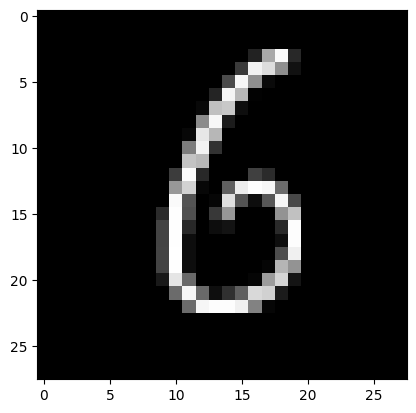

In [ ]:
#Visualize few samples
# What: look at one training image to confirm the data really is what we think it is
# Why : cmap='gray' because MNIST has a single channel - without it matplotlib picks a false-colour map
import matplotlib.pyplot as plt
plt.imshow(x_train[18,:,:],cmap='gray')

# imshow expects pixel values to be between 0 and 1. It remaps it internally to show image in original state.
# If you truly want to see what you current image (after scaling) looks like, run the next cell

In [ ]:
# cv2_imshow(x_train[18,:,:])

# True state of the image at this point - Remember, for humans this is useless, but
# computers are only looking for change in numbers (pixel intensities). Smaller values
# help NN learn with more stability (else your weights would be jumping around a lot)

In [ ]:
# What: shape of the raw training images -> (60000, 28, 28): 60000 images of 28x28 pixels
# Why : notice there is NO channel dimension yet, which is exactly what the next cell fixes
xtrain.shape

(60000, 28, 28)

In [ ]:
# CNN required data to be in the 4D
# first dimension is number of images
# second dimension is number of rows in the image
# Third dimension is number of columns in the image
# Fourth dimension is number of planes in the image( 1 for grayscale, 3 for color)
# Why : Conv2D slides its kernels over (height, width) for every channel, so the channel axis
#       must exist even when there is only one of them
import numpy as np
xtrain1=np.expand_dims(x_train,3)   # What: (60000,28,28) -> (60000,28,28,1)
xtest1=np.expand_dims(x_test,3)

In [ ]:
# What: confirm the extra axis is there -> (60000, 28, 28, 1)
xtrain1.shape

(60000, 28, 28, 1)

<a id="sec3"></a>
## 3. Encode the target column

**What:** the labels arrive as plain integers (`5`, `0`, `4`, ...). We convert each one into a
vector of 10 numbers that is 1 at the position of the correct digit and 0 everywhere else.

**Why:** the network's output layer produces 10 probabilities, and `categorical_crossentropy`
compares those 10 numbers against 10 target numbers. An integer label would not line up with that.
(The alternative is to keep the integers and use `sparse_categorical_crossentropy` instead.)

[&#8593; Back to TOC](#toc)

In [ ]:
# Current state of target - We want it one hot encoded
ytrain[0:10]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8)

In [ ]:
#Encode the target column
# What: 3  ->  [0,0,0,1,0,0,0,0,0,0]   (this is called one-hot encoding)
# Why : it also stops the model from assuming the digits have an order, i.e. that 9 > 8 > 7
ytrain=tf.keras.utils.to_categorical(ytrain,num_classes=10)
ytest=tf.keras.utils.to_categorical(ytest,num_classes=10)

In [ ]:
# What: the first training label as a one-hot vector - exactly one 1, nine 0s
ytrain[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

<a id="sec4"></a>
## 4. Build the CNN

**What:** a small stack - Conv(16) + Pool, Conv(32) + Pool, Flatten, Dense(64), Dense(10).

**Why this shape:** each Conv layer learns filters that respond to a pattern (a stroke, a corner, a
loop); each Pool layer halves the resolution so later layers see a larger part of the digit while
staying cheap. Flatten then turns the stack of feature maps into one vector that the Dense layers
can classify into 10 digits.

[&#8593; Back to TOC](#toc)

In [ ]:
# import the libraries required for CNN
# Why : Sequential = a straight stack of layers, which is all a plain CNN needs
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense

In [ ]:
#Define the architecture of CNN
classifier=Sequential()

# What: 16 kernels of 3x3 sliding over the 28x28x1 image -> output 26x26x16
# Why : 28 - 3 + 1 = 26, a 3x3 kernel with no padding loses one pixel on each border
classifier.add(Conv2D(16,(3,3),input_shape=(28,28,1),activation ='relu'))
# What: 2x2 pooling halves height and width -> 13x13x16
# Why : cheaper, and makes the features tolerant to a digit being drawn a pixel or two off-centre
classifier.add(MaxPooling2D(pool_size=(2,2)))

# What: second block, more filters on a smaller map -> 11x11x32 then 5x5x32
# Why : deeper layers combine simple strokes into more distinctive shapes, so we need more of them
classifier.add(Conv2D(32,(3,3),activation ='relu'))
classifier.add(MaxPooling2D(pool_size=(2,2)))

# What: 5x5x32 feature maps -> one flat vector of 800 numbers
# Why : Dense layers take a 1D vector, not a 3D stack of maps
classifier.add(Flatten())

classifier.add(Dense(units=64,activation='relu'))      # What: hidden layer that mixes the 800 features
# What: 10 outputs - one per digit. Why softmax: it turns the raw scores into probabilities summing to 1
classifier.add(Dense(units=10,activation='softmax'))

In [ ]:
# What: layer-by-layer table of output shapes and parameter counts
# Why : a quick sanity check that the shapes shrink the way we expect (26 -> 13 -> 11 -> 5)
classifier.summary()

<a id="sec5"></a>
## 5. Compile the model

**What:** attach the three things the training loop needs - an optimizer (how weights are
updated), a loss (what is being minimised) and a metric (what we read to judge progress).

**Why these choices:** `adam` adapts the step size per weight so it works well without tuning;
`categorical_crossentropy` matches our one-hot labels and softmax output; `accuracy` is the metric
a human actually cares about here.

[&#8593; Back to TOC](#toc)

In [ ]:
# compilation statergy for the model
# Note: the metric names chosen here ('accuracy') are exactly the names the callbacks below can
#       monitor - 'val_loss', 'val_accuracy', 'loss', 'accuracy'
classifier.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

<a id="sec6"></a>
## 6. Callbacks - EarlyStopping and ModelCheckpoint

**What:** two objects handed to `fit()` that watch the validation loss after every epoch.

* `EarlyStopping` - stop the run once the validation loss has not improved for `patience` epochs.
* `ModelCheckpoint` - write the model to disk, but only when it is the best one seen so far.

**Why they go together:** early stopping decides *when to quit*, the checkpoint decides *what to
keep*. Without the checkpoint, stopping late leaves us holding the weights from the last (slightly
worse) epoch rather than the best one.

[&#8593; Back to TOC](#toc)

In [ ]:
# apply earlystopping callback to stop the iteration if there is no improvement in model performace
                               #for few consecutive iteration defined by 'patience'
# apply model checkpoint callback to save the weights corresponds to the best iteration
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

keras_callback=[
    # monitor      : which number to watch after every epoch
    # patience=3   : allow 3 epochs with no improvement before stopping
    # mode='min'   : for a loss, "better" means smaller (use 'max' when monitoring accuracy)
    # min_delta    : an improvement smaller than this does not count as an improvement at all
    EarlyStopping(monitor='val_loss',patience=3,mode='min',min_delta=0.001),

    # save_best_only=True : overwrite the file only when val_loss beats the best value so far
    # Note: in Keras 3 the checkpoint path must end in .keras (or .weights.h5 for weights only)
    ModelCheckpoint('./Check_Point.keras',monitor='val_loss',save_best_only=True)]

<a id="sec7"></a>
## 7. Train the model with callbacks

**What:** the actual training run. `validation_split=0.2` holds back the last 20% of the
training data so there is a `val_loss` for the callbacks to watch.

**EarlyStopping** will genuinely cut the run short, usually somewhere around epoch 5-8 on MNIST.

[&#8593; Back to TOC](#toc)

In [ ]:
# fit (Train) the model with callbacks
# What: batch_size=32 -> the weights are updated once per 32 images
# Why validation_split: the callbacks monitor 'val_loss', which only exists if fit() has validation data
EPOCHS = 1   # <- raise this (10-20) in class to actually see EarlyStopping trigger

history = classifier.fit(x=xtrain1,y=ytrain,batch_size=32,epochs=EPOCHS,
                         validation_split=0.2,callbacks=keras_callback)

In [ ]:
# What: fit() returns a History object holding the metric value after every epoch
# Why : this is the same data the callbacks saw - handy for plotting the learning curves
history.history

<a id="sec8"></a>
## 8. Alternate callback strategies

**What:** `EarlyStopping` + `ModelCheckpoint` are the common pair, but Keras ships several other
callbacks, and writing your own is a few lines. The table below is the menu; the cells after it set
them all up and run a short training on a small slice of MNIST so you can watch them act.

| Callback | What it does | When to reach for it |
|---|---|---|
| `EarlyStopping(restore_best_weights=True)` | On stopping, rolls the weights back to the best epoch | Almost always - it removes the need for a checkpoint file just to recover the best model |
| `ReduceLROnPlateau` | Multiplies the learning rate by `factor` when the monitored metric stalls | When the model is still improving but has stopped taking big steps - often buys a few more points of accuracy |
| `ModelCheckpoint(save_weights_only=True)` | Saves only the weights, not the architecture | Large models, or when the architecture is already defined in code |
| `ModelCheckpoint` with `{epoch}` in the filename | Keeps one file per epoch instead of overwriting | When you want to compare or roll back to any epoch |
| `CSVLogger` | Appends every epoch's metrics to a `.csv` file | Reporting, or plotting curves after the kernel has been restarted |
| `TerminateOnNaN` | Kills the run the moment the loss becomes NaN | Cheap insurance - a diverged run otherwise burns hours producing nothing |
| `BackupAndRestore` | Snapshots the run so it can resume from where it broke | Long runs on a machine that may be interrupted |
| `TensorBoard` | Streams metrics (and more) to the TensorBoard UI | Comparing many runs visually |
| `LambdaCallback` | Runs a one-line function at a chosen moment | Quick experiments, printing something custom |
| Your own `Callback` subclass | Any rule you can write in Python | Project-specific rules, e.g. "stop as soon as accuracy passes 99%" |

**The one idea behind all of them:** Keras calls the methods `on_epoch_end`, `on_batch_end`,
`on_train_begin` ... at fixed points, hands them the current metrics in `logs`, and a callback can
read those and react - print, save, change the learning rate, or set `self.model.stop_training = True`.

[&#8593; Back to TOC](#toc)

In [ ]:
# What: a callback of our own - stop the moment training accuracy crosses a target
# Why : shows that a callback is just a class with methods Keras calls at known moments
class StopAtAccuracy(tf.keras.callbacks.Callback):

    def __init__(self, target=0.95):
        super().__init__()
        self.target = target                      # What: the accuracy we are happy with

    def on_epoch_end(self, epoch, logs=None):     # What: Keras calls this after every epoch
        logs = logs or {}                         # Why : logs is None if the model has no metrics
        acc = logs.get('accuracy')                # What: the metrics of the epoch just finished
        if acc is not None and acc >= self.target:
            print(f"\nReached {acc:.3f} accuracy - stopping early.")
            self.model.stop_training = True       # What: THIS is the flag that ends the training loop

In [ ]:
# What: build the alternate callback list
# Why : each line is one strategy from the table above, so you can comment any of them in or out
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint, ReduceLROnPlateau,
                                        CSVLogger, TerminateOnNaN, LambdaCallback)

alt_callbacks = [
    # 1. Early stopping that also REWINDS to the best epoch, so no separate file is needed
    EarlyStopping(monitor='val_loss', patience=2, mode='min',
                  restore_best_weights=True, verbose=1),

    # 2. When val_loss stops improving for 1 epoch, halve the learning rate instead of quitting
    #    Why : smaller steps often squeeze out improvement that the larger steps kept overshooting
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5, verbose=1),

    # 3. One checkpoint file PER EPOCH - the epoch number is filled into the filename by Keras
    #    Why : lets you go back to any epoch, not just the best one
    ModelCheckpoint('./ckpt_epoch_{epoch:02d}.weights.h5', save_weights_only=True, verbose=0),

    # 4. Write every epoch's metrics to a csv, so the curves survive a kernel restart
    CSVLogger('./training_log.csv'),

    # 5. Abort immediately if the loss blows up to NaN
    TerminateOnNaN(),

    # 6. A one-off hook without writing a class
    LambdaCallback(on_epoch_end=lambda epoch, logs: print(f"   [lambda] epoch {epoch} done, val_loss={logs['val_loss']:.4f}")),

    # 7. Our own rule from the cell above
    StopAtAccuracy(target=0.95),
]
print(f"{len(alt_callbacks)} callbacks ready")

In [ ]:
# What: a short demo run - a fresh copy of the same architecture, 6000 images, a few epochs
# Why : small and fast on purpose. The point is to WATCH the callbacks fire, not to train a good model
demo = Sequential([
    Conv2D(16,(3,3),input_shape=(28,28,1),activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(10,activation='softmax')])
demo.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

demo_history = demo.fit(xtrain1[:6000], ytrain[:6000],
                        batch_size=32, epochs=5, validation_split=0.2,
                        callbacks=alt_callbacks, verbose=1)

In [ ]:
# What: the csv that CSVLogger wrote, and the per-epoch checkpoint files that were created
# Why : proof that the callbacks really ran, and a reminder of what they leave behind on disk
import pandas as pd, glob
print(pd.read_csv('./training_log.csv'))
print()
print("checkpoint files:", sorted(glob.glob('./ckpt_epoch_*.weights.h5')))

<a id="sec9"></a>
## 9. Save the trained model

**What:** write the whole model - architecture *and* learned weights - into a single file.

**Why:** the next session reuses these learned digit features instead of training from scratch,
which is the idea behind transfer learning. Keras 3 prefers the native `.keras` format; `.h5` still
works and is kept here so the file name matches what the next notebook expects.

[&#8593; Back to TOC](#toc)

In [ ]:
# Save the weights, this weight we are going to use in out next experiment on Transfer Learning
# Note: Keras prints a "legacy format" notice for .h5 - harmless. The modern equivalent is
#       classifier.save('my_digit_model.keras')
classifier.save('my_digit_model.h5')

In [ ]:
# What: load it straight back to prove the file is complete and usable
# Why : a saved model that cannot be reloaded is worse than no saved model
reloaded = tf.keras.models.load_model('my_digit_model.h5')
print("reloaded model output shape:", reloaded.output_shape)